<!-- twin: dataset-specific -->
# Lab 3: RAG Improvements

In this lab we use metric-driven experimentation to improve the RAG system from Lab 2. We will do so in four parts:
1. Working from a LlamaParse-parsed corpus
2. Hybrid search with RRF
3. Prompts: exploring the input prompts for llama-index RAG implementations
4. Contextual retrieval

An optional cell at the end tries small-to-big expansion.

**Dataset: CalHR employee benefits.** 20 documents, 255 chunks at 384/96.


**After this lab you can** compare dense, keyword and hybrid (RRF) retrieval on every golden question and say whether a difference is real, with an interval.

You can also say what a parser, a prompt and contextual retrieval each change, and how to measure that change.


_____
## Imports + Downloads

<!-- twin: dataset-specific -->
The retrieval in this lab runs entirely inside this notebook. Two routes over the same
20 documents:

- **dense**, the vector search you built in Lab 2
- **keyword**, BM25, a classic ranking function over the words themselves

and then a **hybrid** that fuses the two. Nothing is hosted, so nothing can be rate limited
or suspended for the whole room at once.

The corpus arrives pre-parsed and pre-embedded as a single file, because the parsing step
takes about a minute per document.


In [ ]:
# Every version here is pinned, including the llama-index satellites. An unpinned
# dependency is a bet that nothing upstream changes between now and the moment you run
# this, and that bet is how a notebook that worked last week stops working today.
%pip install -q \
  litellm==1.102.0 "openai>=2.20.0,<3.0.0" \
  llama-index==0.14.24 llama-index-readers-file==0.7.0 fonttools==4.65.0 \
  llama-index-vector-stores-chroma==0.6.0 \
  llama-index-embeddings-litellm==0.6.0 llama-index-llms-openrouter==0.6.0 \
  llama-index-retrievers-bm25==0.8.0 bm25s==0.3.14 PyStemmer==2.2.0.3 \
  chromadb==1.5.9 pandas==2.2.3 pyarrow==26.0.0 nest_asyncio==1.6.0 tiktoken==0.14.0


In [ ]:

import os
import asyncio
import logging
import zipfile
import pandas as pd

import Stemmer
import chromadb

from llama_index.core import VectorStoreIndex, Settings
from llama_index.core.schema import TextNode
from llama_index.core.retrievers import QueryFusionRetriever
from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.retrievers.bm25 import BM25Retriever
from llama_index.vector_stores.chroma import ChromaVectorStore
from llama_index.embeddings.litellm import LiteLLMEmbedding

# llama_index.llms.openai.OpenAI validates model names against its own table of OpenAI
# models and raises on an id like "openai/gpt-4.1-mini", even with a correct api_base.
# OpenRouter (which extends OpenAILike) does not.
from llama_index.llms.openrouter import OpenRouter

# bm25s logs every step of building its index at DEBUG, which fills the cell with lines
# nobody in the room needs to read. The retriever is unaffected.
logging.getLogger("bm25s").setLevel(logging.WARNING)

# Dollar amounts in answers would otherwise be typeset as maths in table output.
pd.set_option("display.html.use_mathjax", False)


In [ ]:
# twin: dataset-specific
# Every setting this lab shares with the other labs comes from one file in the public repo.
# Change a value there, not here. Retrieval results are only comparable when the chunk size,
# the embedding model and the generator are held still, and this is what holds them still.
import json, urllib.request

DATASET = 'calhr'   # one notebook per dataset, on purpose; no picker here

CONFIG_URL = "https://raw.githubusercontent.com/ndecavel/tdwi-workshop-labs/36c0a68ca026b555be4ad5175278173fc6ce407b/data/dataset_config.json"
# The small assets this lab fetches (the table exhibit, the chunk-to-page map) live in the same
# repo at the same pinned commit as the config, so moving the pin moves all of them together.
ASSET_BASE = CONFIG_URL.split('/data/')[0]
urllib.request.urlretrieve(CONFIG_URL, "/content/dataset_config.json")
CFG = json.load(open("/content/dataset_config.json"))
SHARED, DS = CFG['shared'], CFG['datasets'][DATASET]
print(f"dataset={DATASET} ({DS['label']}), chunking={DS['chunk_size']}/{DS['chunk_overlap']}")

urllib.request.urlretrieve(DS['golden_url'], "/content/Golden_Test_Data_DeepEval.csv")
golden_df = pd.read_csv('/content/Golden_Test_Data_DeepEval.csv')
golden_df = golden_df.drop(columns=[c for c in golden_df.columns if c.startswith('Unnamed')])
golden_df = golden_df.rename(columns={'input':'question', 'expected_output':'ground_truth'})

In [ ]:
GPT_MODEL   = SHARED['generator_model']   # generator, non-reasoning on purpose (see below)
EMBED_MODEL = SHARED['embed_model']

# The corpus below was embedded with EMBED_MODEL. Query-time embeddings must use the same
# model or dense retrieval quietly gets worse instead of failing.
CORPUS_URL = DS['corpus_url']
assert CORPUS_URL, (
    f"dataset_config.json carries no corpus_url for {DATASET!r} yet. The pre-parsed "
    "corpus has to be published as a release asset before this notebook can run.")

# How many golden questions are shown row by row: in the fusion trace, the prompt task and
# the expansion table. Every score in this lab uses all of the
# quality-1.0 golden questions.
SAMPLE_SIZE = SHARED['lab_sample_size']

# Ceiling on concurrent in-flight calls, so one attendee cannot fire the whole batch at once.
MAX_CONCURRENCY = SHARED['max_concurrency']

TOP_K = SHARED['similarity_top_k']
CONTEXT_WINDOW = SHARED['context_window']
MAX_TOKENS = SHARED['max_tokens']         # None: no ceiling sent at all. See below.

# context_window and max_tokens are both set explicitly, and both matter.
#
# llama-index's defaults are context_window=3900 and max_tokens=256. They are not
# OpenRouter's and not the model's: they are llama-index-wide constants
# (DEFAULT_CONTEXT_WINDOW, DEFAULT_NUM_OUTPUTS in llama_index/core/constants.py) that date
# from the GPT-3 era, when 4,097 tokens was the whole window. Nothing updates them per model.
#
# Both defaults broke this lab silently:
#   * Five retrieved chunks are about 4,200 tokens, over the 3,900 window, so llama-index
#     split the context and answered over several "refine" passes. Slower, worse, no warning.
#     Measured: 1.7 generator calls per question instead of 1.
#   * max_tokens is the budget for EVERYTHING the model emits, and on a reasoning model that
#     includes reasoning tokens you never see. gpt-5-mini spent all 256 thinking and returned
#     llama-index's literal "Empty Response", which looked like a model that knew nothing.
#
# MAX_TOKENS is None here, which means the parameter is left out of the request entirely and
# the model generates up to its own limit. Note the trap: passing None and omitting the
# argument are opposites in this class. Omit it and you inherit DEFAULT_NUM_OUTPUTS = 256,
# the setting that caused the failure above. None removes the ceiling; leaving it out
# reinstates the worst possible one.
#
# A ceiling is also not a cost control: you are billed for tokens actually generated, not for
# the cap. Raising max_tokens WITHOUT raising context_window fails outright, since llama-index
# computes available context as window minus max_tokens:
#   ValueError: Calculated available context size -300 was not non-negative.

In [ ]:
# twin: dataset-specific
# Your OpenRouter key. One key covers every model call in this notebook: chat and
# embeddings both go through OpenRouter.
#
# Get a key at https://openrouter.ai/keys. Then either add it to Colab's Secrets
# panel (the key icon in the left sidebar) under the name OPENROUTER_API_KEY and
# switch on notebook access, or paste it when this cell asks. On the workshop day
# the hub handed one out instead, and it still will if a workshop is running.
import json, os, urllib.error, urllib.request
from getpass import getpass

WORKSHOP_HUB = "https://tdwi-workshop-hub.vercel.app"

def load_openrouter_key(hub=WORKSHOP_HUB):
    """Find a key and load it into this session. Says where it came from, never what it is."""
    if os.environ.get("OPENROUTER_API_KEY"):
        return "this session"
    try:
        from google.colab import userdata
        key = userdata.get("OPENROUTER_API_KEY")
        if key:
            os.environ["OPENROUTER_API_KEY"] = key.strip()
            return "Colab Secrets"
    except Exception:
        pass  # not in Colab, no secret by that name, or notebook access is switched off
    try:
        request = urllib.request.Request(
            f"{hub}/api/env", data=b"{}", headers={"content-type": "application/json"})
        with urllib.request.urlopen(request, timeout=20) as response:
            os.environ.update(json.load(response))
        return "the workshop hub"
    except Exception:
        pass  # the hub only hands out keys while a workshop is running
    key = getpass("Paste your OpenRouter API key (get one at https://openrouter.ai/keys): ").strip()
    if not key:
        raise SystemExit(
            "No key was pasted, so nothing in this notebook can call a model. Get one at "
            "https://openrouter.ai/keys, then run this cell again.")
    os.environ["OPENROUTER_API_KEY"] = key
    return "the key you pasted"

print("OpenRouter key loaded from", load_openrouter_key())


# No product catalogue here: the documents are the catalogue. Where each PDF came from,
# and the five that CalHR publishes only as non-downloadable flipbooks, are recorded in
# data/calhr/MANIFEST.md in the workshop repo.


____

In [ ]:
# twin: dataset-specific
# The 20 documents, as published. Six handbooks hold 90% of the text; the 14 flyers are
# two pages each and are kept because they give the file_name metadata something to
# discriminate on during retrieval.
catalog = pd.DataFrame(
    [("2026 CoBen Handbook", "handbook", 13),
     ("2026 Dental Active Handbook", "handbook", 27),
     ("2026 Dental Retiree Handbook", "handbook", 27),
     ("2026 FlexElect Handbook", "handbook", 26),
     ("2026 Long-Term Disability Benefits Guide", "handbook", 25),
     ("2027 Benefit Summary for Active State Employees", "handbook", 39),
     ("2026 Cash Options Flyer", "flyer", 2),
     ("2026 Dependent Care Reimbursement Account Flyer", "flyer", 2),
     ("2026 EAP Core Flyer", "flyer", 3),
     ("2026 EAP Digital Emotional Wellbeing", "flyer", 2),
     ("2026 EAP Financial Wellbeing", "flyer", 2),
     ("2026 EAP Legal Services", "flyer", 2),
     ("2026 EAP LifeMart Discount Center", "flyer", 2),
     ("2026 EAP Manager Support", "flyer", 2),
     ("2026 EAP Website Flyer", "flyer", 2),
     ("2026 EAP Wellbeing Coaching", "flyer", 2),
     ("2026 EAP Work Life Services", "flyer", 2),
     ("2026 FlexElect Reimbursement Account Flyer", "flyer", 2),
     ("2026 Long-Term Disability Flyer", "flyer", 2),
     ("2026 Medical Reimbursement Account Flyer", "flyer", 2)],
    columns=["title", "kind", "pages"])

print(catalog.groupby("kind")["pages"].agg(["count", "sum"]))
catalog.head(6)

<!-- twin: dataset-specific -->
The six handbooks above are where nearly all of the retrievable text lives, and they are also where the hard questions come from. Note the two dental handbooks. About half of the retiree handbook's text appears word for word in the active one, which makes them genuinely confusable and gives the "retrieved the wrong document" failure a real example rather than a staged one.

In [ ]:
# Everything routes through OpenRouter, so one key covers the generator and
# the embeddings.
llm = OpenRouter(model=GPT_MODEL, api_key=os.environ["OPENROUTER_API_KEY"],
                 context_window=CONTEXT_WINDOW, max_tokens=MAX_TOKENS)
embed_model = LiteLLMEmbedding(model_name=EMBED_MODEL, embed_batch_size=100)

Settings.llm = llm
Settings.embed_model = embed_model


____
## 1. Working from a LlamaParse-parsed corpus

This lab does not parse anything. It loads a corpus that was parsed once, ahead of time. The next two cells show how that parse was run and what it did.


In [ ]:
# twin: dataset-specific
### This is how the corpus you are about to download was produced. It is commented out
### because LlamaParse takes roughly a minute per document, and there are 20 of them.
### The parsed result is published as a release asset, so nobody pays that cost twice.
###
### Note `output_tables_as_HTML=True`. That is why the raw parse came back with <table>
### markup rather than markdown, which is rewritten before the corpus ships. See
### scripts/build_improved_nodes.py in the workshop repo.
# import nest_asyncio
# nest_asyncio.apply()

# parser = LlamaParse(
#     api_key=### Here is where you would input your Llama Parse API Key,
#     result_type="markdown",
#     num_workers=4,
#     parse_mode="parse_page_with_agent",
#     model="openai-gpt-5-mini",
#     outlined_table_extraction=True,
#     output_tables_as_HTML=True,
#     verbose=True
# )

# import glob
# for file in glob.glob(f"{DOCS_FOLDER_PATH}/*.pdf"):
#   documents[file] = await parser.aparse(file)


<!-- twin: dataset-specific -->
### What the parse did for this corpus

LlamaParse (from LlamaIndex) reads each PDF page with a language model instead of only pulling out its text layer. For this corpus, the settings are the ones in the commented-out cell above: agent mode (`parse_mode="parse_page_with_agent"`, model `openai-gpt-5-mini`), with tables emitted as HTML (`output_tables_as_HTML=True`).

All 20 documents went through LlamaParse at the agentic tier, with the version pinned to a date so the parse can be reproduced. After the markdown rewrite, every chunk was matched back to the page it came from.

The corpus build then rewrote the HTML tables as markdown before anything was split or embedded. What that conversion costs is shown in the table exhibit a few cells down.

Background: [LlamaParse launch post (2024)](https://www.llamaindex.ai/blog/launching-the-first-genai-native-document-parsing-platform).


In [ ]:
## 1. Download the pre-parsed corpus and load it into a local Chroma collection.
## Nothing is embedded here: the vectors ship with the file.
import urllib.request

urllib.request.urlretrieve(CORPUS_URL, "/content/corpus.parquet")
corpus = pd.read_parquet("/content/corpus.parquet")
print(f"{len(corpus)} chunks over {corpus.file_name.nunique()} documents, "
      f"{len(corpus.embedding.iloc[0])}-dimensional embeddings")

# Contextual retrieval ships as two extra columns, built once and published with the corpus.
# If this
# corpus predates them the last section of the lab skips itself and says so.
HAS_CONTEXT = ('embedding_contextual' in corpus.columns
               and corpus['embedding_contextual'].notna().all()
               and corpus.get('context', pd.Series(dtype=str)).fillna('').str.len().gt(0).any())
print(f"contextual vectors present: {HAS_CONTEXT}")

nodes = [
    TextNode(
        id_=row.id,
        text=row.text,
        embedding=list(row.embedding),
        metadata={"file_name": row.file_name, "page_label": row.page_label},
    )
    for row in corpus.itertuples()
]

chroma_client = chromadb.EphemeralClient()
chroma_collection = chroma_client.get_or_create_collection(
    name="improved_vector_store",
    configuration={"hnsw": {"space": "cosine"}},
)
vector_store = ChromaVectorStore(chroma_collection=chroma_collection)

# Chroma refuses a single .add() over 5461 records.
BATCH = 4000
for i in range(0, len(nodes), BATCH):
    vector_store.add(nodes[i:i + BATCH])

print(f"Loaded {chroma_collection.count()} chunks into Chroma with no embedding calls")

# Lookups by chunk id, used by the retrieval metrics and the expansion cell further down.
FILE_OF = dict(zip(corpus.id, corpus.file_name))
ORIG_TEXT = dict(zip(corpus.id, corpus.text))

# Which PHYSICAL pdf page each chunk came from (None where it could not be placed).
# page_label is not that: for CalHR it is the number printed on the page, which drifts
# from the physical page in the long documents.
with urllib.request.urlopen(f"{ASSET_BASE}/{DS['chunk_pages']}", timeout=30) as resp:
    CHUNK_PAGES = json.load(resp)['pages']

In [ ]:
# twin: dataset-specific
### The corpus file was built from the LlamaParse output by scripts/build_improved_nodes.py
### in the workshop repo, run with --from-parsed. All 20 documents went through LlamaParse
### at tier=agentic with the version pinned to a date, so the parse can be reproduced.
### 255 chunks at 384/96, every chunk matched back to its page, and 223 of them carrying
### the page number printed on the page itself.
###
### 384/96, rather than the 1024/200 this workshop uses for the paint corpus, is deliberate.
### This corpus is a sixth the size. At 1024/200 it splits into about 100 chunks, so a
### top-5 query would return 5% of everything there is, and dense retrieval would find the
### right chunk more or less by accident.

### One table, three ways

A table's meaning lives in its relationships: which plan column a number sits under, which row label it belongs to, which footnote applies to it. Markdown pipe tables cannot express merged cells (`rowspan` and `colspan`), so a merged header gets repeated or dropped. Every number can survive the conversion while the link between a number and its header breaks.

The cell below shows one complex table from this corpus three ways, under a crop of the PDF page it came from:

- **PyMuPDF text**, a plain text-layer extractor's reading of the page (Lab 2's own reader, pypdf, is the same kind of extractor).
- **Shipped markdown**, shown raw, because this is exactly what the splitter and the embedder received.
- **HTML**, rendered, with the merged cells kept. This view was rebuilt for the exhibit from PyMuPDF's table finder, because LlamaParse's own HTML for this page was not available. It shows what HTML can keep, not what LlamaParse emitted.

Look at the page crop first, then check each view against it. It makes no model calls.


In [ ]:
## Show one complex table three ways. Display only: nothing is parsed here and no model is called.
import html as htmllib
from IPython.display import HTML, display

try:
    with urllib.request.urlopen(f"{ASSET_BASE}/{DS['table_exhibit']}", timeout=30) as resp:
        exhibit = json.load(resp)
except Exception:
    exhibit = None
    print("The table exhibit could not be downloaded, so this cell is skipped. Nothing later "
          "in the lab depends on it. Run the cell again to retry.")

if exhibit:
    esc = htmllib.escape
    where = f"{exhibit['source_pdf']}, physical page {exhibit['page']}"
    if exhibit.get('printed_page'):
        where += f", printed page {exhibit['printed_page']}"

    def panel(title, note, body, grow=1):
        return (f'<div class="tx-panel" style="flex-grow:{grow}"><div class="tx-title">{esc(title)}</div>'
                f'<div class="tx-note">{esc(note)}</div>{body}</div>')

    panels = [
        panel("PyMuPDF text", "A plain text-layer extractor's reading.",
              f"<pre>{esc(exhibit['pymupdf_text'])}</pre>"),
        panel("Shipped markdown", "What the splitter and the embedder received.",
              f"<pre>{esc(exhibit['markdown'])}</pre>"),
        panel("HTML, rendered", exhibit['html_source'], exhibit['html'], grow=2),
    ]
    display(HTML(f'''
<style>
  .tx {{ background:#fff; color:#1a1a1a; font:13px/1.4 sans-serif; padding:12px; border-radius:6px; }}
  .tx-head {{ font-weight:600; margin-bottom:8px; }}
  .tx img {{ max-width:min(100%, 760px); border:1px solid #d0d0d0; }}
  .tx-row {{ display:flex; flex-wrap:wrap; gap:12px; margin-top:12px; }}
  .tx-panel {{ flex:1 1 280px; min-width:0; overflow:auto; }}
  .tx-title {{ font-weight:600; }}
  .tx-note {{ color:#555; font-size:12px; margin-bottom:4px; }}
  .tx pre {{ white-space:pre-wrap; margin:0; padding:8px; background:#f6f6f6; font:12px/1.35 monospace; color:#1a1a1a; }}
  .tx table {{ border-collapse:collapse; }}
  .tx td, .tx th {{ border:1px solid #d0d0d0; padding:3px 7px; vertical-align:top; text-align:left !important; color:#1a1a1a; }}
  .tx th {{ background:#f0f0f0; }}
</style>
<div class="tx tex2jax_ignore mathjax_ignore">
  <div class="tx-head">{esc(exhibit['title'])}: {esc(where)}</div>
  <img src="data:image/png;base64,{exhibit['image_png_b64']}" alt="Crop of the PDF page">
  <div class="tx-row">{''.join(panels)}</div>
</div>'''))


<!-- twin: dataset-specific -->
**What to look at in this table** (the PPO plan coverage table, 2027 Benefits Summary for Active State Employees, physical page 16, printed page 14):

- "PPO PLANS" spans the three plan columns. The HTML keeps it as one cell. The markdown repeats it three times, once per column, and leaves the corner cell empty.
- The three plan names sit one row below, so the header is two rows in the HTML and a repeated label plus a row of names in the markdown.
- Footnote markers are `<sup>` in the HTML. In the PyMuPDF text and in places in the markdown they are plain digits glued to the words: "No charge4", "PLUS1,2". A reader, or an embedder, cannot tell the 4 from part of the text.
- The PyMuPDF text spaces out some headers letter by letter ("P P O P L A N S"), which is how the page's typography came through. A keyword search for "PPO" does not match that.


In [ ]:
index = VectorStoreIndex.from_vector_store(vector_store, embed_model=Settings.embed_model)


____
## 2. Hybrid search with RRF

The corpus is loaded. Now we change how we search it. First, how the two kinds of search are
combined, then the three retrievers we compare.


### Understanding hybrid search with RRF

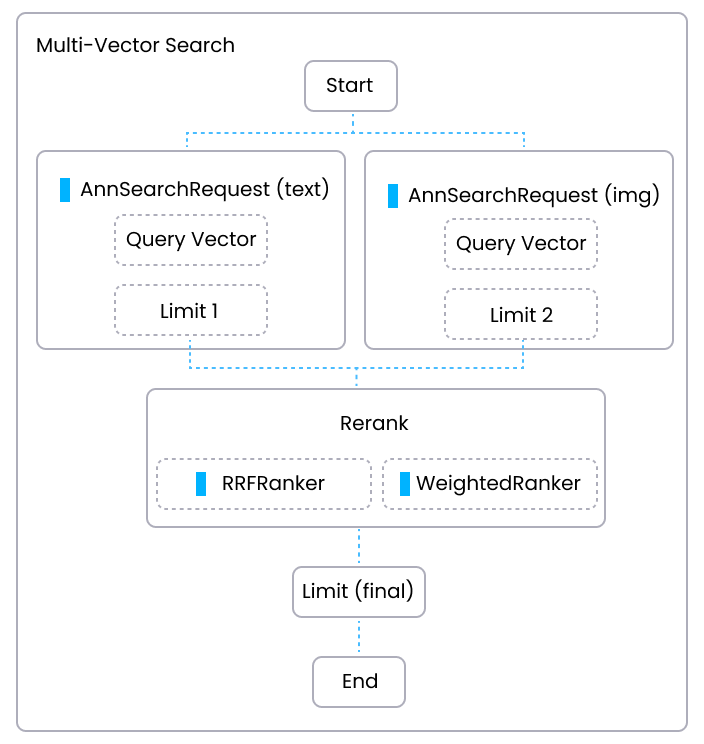

Two ways to combine the results of a dense (vector) search and a keyword search:

#### Weighted scoring
Give each retrieval route a weight and add the weighted scores. This suits the case where
you know one route matters more than another, for example when a text description should
count for more than a colour histogram. It needs the two routes' scores to be comparable,
which is the hard part: a cosine similarity and a BM25 score are not on the same scale.

#### Reciprocal Rank Fusion (RRF)
RRF ignores the scores entirely and uses only the **rank** each route assigned. A document
at position *p* in a route's list contributes `1 / (k + p)`, and a document's final score is the sum of
that across routes. LlamaIndex counts the top result as position 0, so first place adds
`1/60`, second place `1/61`, and so on. Many write the same formula with the top result as
rank 1; the shape is identical. You will reproduce it by hand further down. Because only ranks are used, the two routes never have to agree on what
a score means, which is why RRF is the usual default when there is no clear reason to
prefer one route.

`k` damps the advantage of the very top ranks; a larger `k` flattens the curve. The constant
is conventionally 60, which is what the LlamaIndex `QueryFusionRetriever` you are about to
build uses. It is fixed inside the library, not a setting you pass. Hosted vector databases implement the same algorithm; here it runs
in the notebook, so you can read it.


In [ ]:
## 2. Build the three retrievers we are comparing.

def engines_at(k):
    """The three retrievers, each returning its top k. The metric cell below asks for every
    depth in turn (5, 10 and 20), so they are built here as a function of k."""
    # a) naive (dense): dense vectors only, the Lab 2 approach
    dense = index.as_retriever(similarity_top_k=k)

    # b) keyword (BM25): running in this notebook over the same nodes. No database involved.
    bm25 = BM25Retriever.from_defaults(
        nodes=nodes,
        similarity_top_k=k,
        stemmer=Stemmer.Stemmer("english"),
        language="english",
    )

    # c) hybrid (RRF): fuse the two by reciprocal rank.
    # num_queries=1 stops the retriever generating extra query variations with the LLM, which
    # would add a model call per question and confound the comparison.
    hybrid = QueryFusionRetriever(
        [dense, bm25],
        mode="reciprocal_rerank",
        num_queries=1,
        similarity_top_k=k,
        use_async=True,
    )
    return {"naive (dense)": dense, "keyword (BM25)": bm25, "hybrid (RRF)": hybrid}

dense_retriever, bm25_retriever, hybrid_retriever = engines_at(TOP_K).values()

# The prompt task further down answers with the hybrid retriever.
hybrid_query_engine = RetrieverQueryEngine.from_args(hybrid_retriever, llm=llm)

# synthetic_input_quality is a score the question generator assigned itself. Keeping only
# the 1.0 rows drops questions that were malformed before anyone tried to answer them.
sample_test_df = golden_df[golden_df['synthetic_input_quality'] == SHARED['quality_filter']]
sample_test_df = sample_test_df.sample(SAMPLE_SIZE, random_state=SHARED['random_state'])
# The same numbered list is printed in Lab 2, so the two samples can be compared line by line.
for n, q in enumerate(sample_test_df['question'], 1):
    print(f"{n:>2}. {q[:60]}")

print(f"Every score below uses all the quality-1.0 golden questions. The {len(sample_test_df)} above are the ones read row by row.")


### Measuring retrieval directly

The question this lab asks of every change is whether the passage that answers a question reached the model. The golden set records that passage (its `context` column) and the file it came from (`source_file`), so retrieval can be scored without a model reading anything. Four numbers, each over the top k chunks a retriever returns:

- **hit@k**: some chunk in the top k holds the question's source passage.
- **source hit@k**: the same, but the chunk must come from the question's own source file.
- **recall@k**: the share of the passage that the k chunks carry between them. This is the number that says whether the model was handed what it needs: a passage split across two chunks can score no hit and still be mostly there.
- **MRR**: one divided by the rank of the first chunk that holds the passage (0 if none of the k does), averaged over the questions. Rank 1 scores 1.0, rank 2 scores 0.5, rank 5 scores 0.2.

"Holds the passage" needs a stated rule, because the golden passages came from a plain text extractor's output and the chunks are LlamaParse markdown, so the two almost never match character for character. The rule: strip markup, lowercase, split into words, cut both texts into overlapping 6-word phrases, and call a chunk a match when it holds at least half of the passage's phrases. The 6 and the one half are `SHARED['retrieval_metrics']` in the config, next to the depths and the number of resamples used for the intervals.

Every quality-1.0 golden question is scored, at k = 5, 10 and 20. The next cell is the same cell Lab 2-B ran, word for word, so a score here means what it meant there. It makes no model call except one batched embedding of the questions. Run it, then the cell after it, which does the scoring.


In [ ]:
## Retrieval metrics. Lab 2 and Lab 3 run this same cell, word for word, so a score in one lab
## means exactly what it means in the other. A check in the workshop repo fails if the copies differ.
## Nothing here calls a model except embed_questions, which makes one batched call per 100 questions.
import ast, functools, os, re, unicodedata
import numpy as np
import pandas as pd
import tiktoken
from llama_index.core import Settings
from llama_index.core.schema import QueryBundle

RM = SHARED['retrieval_metrics']     # shingle_size, hit_threshold, depths, ci_resamples
ENCODING = tiktoken.get_encoding("o200k_base")   # the tokenizer of the gpt-4.1 family the labs generate with

@functools.lru_cache(maxsize=None)
def words_of(text):
    """Lowercase words, with markup and punctuation out of the way, so a PDF line and a markdown table compare."""
    text = re.sub(r"</?[A-Za-z][A-Za-z0-9]*(?:\s[^<>]*)?/?>", " ", text)   # HTML tags only; a bare "< 50" is text
    text = re.sub(r"!?\[([^\]]*)\]\([^)]*\)", r"\1", text)               # links and images keep their label
    text = re.sub(r"^\s*\|?[\s:|-]{3,}\|?\s*$", " ", text, flags=re.M)    # markdown table rule rows
    text = re.sub(r"[|#*_`>~]", " ", text)                                  # table pipes, headers, emphasis
    text = unicodedata.normalize("NFKC", text).lower()                      # a ligature glyph becomes its letters
    text = re.sub(r"[-\u2010-\u2015]", " ", text)                           # hyphens and dashes split words
    return tuple(re.findall(r"[^\W_]+", text))

@functools.lru_cache(maxsize=None)
def phrases_of(text):
    """Every run of shingle_size consecutive words in the text."""
    words, n = words_of(text), RM['shingle_size']
    return frozenset(words[i:i + n] for i in range(len(words) - n + 1))

def share_found(passage, texts):
    """The share of the passage's phrases that appear in at least one of the texts. A passage too
    short to have a phrase counts as found (1.0) when its words appear, in order, in one text."""
    wanted = phrases_of(passage)
    if not wanted:
        words = " ".join(words_of(passage))
        return float(bool(words) and any(f" {words} " in f" {' '.join(words_of(t))} " for t in texts))
    return len(wanted & frozenset().union(*map(phrases_of, texts))) / len(wanted)

@functools.lru_cache(maxsize=None)
def tokens_in(text):
    return len(ENCODING.encode(text))

def holds(text, passage):
    """A chunk holds the passage when at least hit_threshold of the passage's phrases are in it."""
    return share_found(passage, [text]) >= RM['hit_threshold']

def passage_of(context_cell):
    """The golden `context` column is a stringified list of passages; join them into one."""
    return " ".join(str(p) for p in ast.literal_eval(context_cell))

def golden_questions(golden_df):
    """Every golden question the generator scored quality_filter, with its passage and source file."""
    frame = golden_df.rename(columns={'input': 'question', 'expected_output': 'ground_truth'})
    frame = frame[frame['synthetic_input_quality'] == SHARED['quality_filter']].reset_index(drop=True)
    return frame.assign(passage=frame['context'].map(passage_of),
                        source=frame['source_file'].map(os.path.basename))

def embed_questions(questions):
    """The questions as query bundles with their vectors filled in. The embedding model reads a
    question and a passage the same way, so one batch call gives the vectors one call each would."""
    questions = list(questions)
    vectors = Settings.embed_model.get_text_embedding_batch(questions)
    return [QueryBundle(query_str=q, embedding=v) for q, v in zip(questions, vectors)]

def score_retrieval(ranked, passage, source, k):
    """Score the top k of one ranked list of (file name, chunk text) pairs against one question."""
    top = ranked[:k]
    first = next((i for i, (_, text) in enumerate(top, 1) if holds(text, passage)), None)
    return {"hit": first is not None,                                         # a chunk holds the passage
            "source hit": any(f == source and holds(t, passage) for f, t in top),   # ... from the question's own file
            "recall": share_found(passage, [text for _, text in top]),        # share of the passage the model is handed
            "MRR": 1 / first if first else 0.0,                               # 1 / rank of the first chunk that holds it
            "tokens": sum(tokens_in(text) for _, text in top)}                # what the k chunks cost to send

def score_engines(engines_at, frame, bundles, text_of, depths=None):
    """One row per engine, depth and question. engines_at(k) returns {name: retriever}, and
    text_of(result) the chunk text to score, which is always the text the document said."""
    rows = []
    for k in depths or RM['depths']:
        for engine, retriever in engines_at(k).items():
            for n, (bundle, passage, source) in enumerate(zip(bundles, frame['passage'], frame['source']), 1):
                ranked = [(r.node.metadata['file_name'], text_of(r)) for r in retriever.retrieve(bundle)]
                rows.append({"engine": engine, "k": k, "Q #": n, **score_retrieval(ranked, passage, source, k)})
    return pd.DataFrame(rows)

def summary_at(scores, k):
    """Mean of each metric at depth k, one row per engine, in the order the engines were scored.
    hit, source hit and recall are percentages; MRR is out of 1.0."""
    table = scores[scores['k'] == k].groupby('engine', sort=False)[["hit", "source hit", "recall", "MRR"]].mean()
    table[["hit", "source hit", "recall"]] *= 100
    return table.round({"hit": 1, "source hit": 1, "recall": 1, "MRR": 3}).add_suffix(f"@{k}")

def by_depth(scores, engine):
    """One engine's metrics at every depth k: percentages, MRR out of 1.0, mean tokens of chunk text."""
    table = scores[scores['engine'] == engine].groupby('k')[["hit", "source hit", "recall", "MRR", "tokens"]].mean()
    table[["hit", "source hit", "recall"]] *= 100
    return table.round({"hit": 1, "source hit": 1, "recall": 1, "MRR": 3, "tokens": 0})

def paired_interval(a, b):
    """The mean of a - b over the same questions, and a 95% interval for it: resample the
    questions with replacement ci_resamples times and keep the middle 95% of the means."""
    diff = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    draws = np.random.default_rng(SHARED['random_state']).integers(0, len(diff), (RM['ci_resamples'], len(diff)))
    means = diff[draws].mean(axis=1)
    return diff.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

def files_holding(frame, chunks):
    """For each question, the files whose chunks hold its passage. chunks: (file name, text) pairs."""
    return [sorted({f for f, t in chunks if holds(t, p)}) for p in frame['passage']]

In [ ]:
## Score every quality-1.0 golden question with the three retrievers, at k = 5, 10 and 20.
## The only model call is one batched embedding of the questions.
frame = golden_questions(golden_df)
bundles = embed_questions(frame['question'])
# Later cells look a question's vector up here instead of embedding it again.
BUNDLE = dict(zip(frame['question'], bundles))

def chunk_id_of(retrieved):
    return retrieved.node.node_id.removeprefix("ctx-")

def original_text(retrieved):
    """Always the chunk's ORIGINAL text, so text added later (generated context) cannot create a hit."""
    return ORIG_TEXT[chunk_id_of(retrieved)]

scores = score_engines(engines_at, frame, bundles, text_of=original_text)
print(f"{len(frame)} questions, three retrievers, k = {', '.join(map(str, RM['depths']))}.")
print(f"At k = {TOP_K}: hit, source hit and recall are percentages; MRR is out of 1.0.")
summary = summary_at(scores, TOP_K)
display(summary)

# The same four numbers at every depth, for each retriever. tokens is the mean text sent to the model.
depth_table = pd.concat({engine: by_depth(scores, engine) for engine in summary.index}, names=["engine"])
display(depth_table)
print("What each engine finds, and what it costs in tokens, as k grows from 5 to 20.")

# The ceilings: what no retriever over this corpus can beat. Does any chunk hold the passage at all?
holding = files_holding(frame, list(zip(corpus.file_name, corpus.text)))
held = sum(bool(files) for files in holding)
in_several = sum(len(files) > 1 for files in holding)
ALL = frozenset().union(*map(phrases_of, corpus.text))      # every phrase anywhere in the corpus
covered = float(np.mean([len(phrases_of(p) & ALL) / len(phrases_of(p)) for p in frame['passage'] if phrases_of(p)]))
print(f"Ceilings: some chunk of this corpus holds the passage for {held} of {len(frame)} questions, "
      f"and {in_several} of the passages sit in more than one document.")
print(f"{covered:.1%} of all the golden passages' phrases appear somewhere in the corpus.")

print("RETRIEVAL " + json.dumps({
    "n": len(frame), "k": TOP_K,
    "summary": summary.to_dict(orient="index"),
    "hybrid_by_depth": by_depth(scores, "hybrid (RRF)").reset_index().to_dict(orient="records"),
    "ceilings": {"held": held, "in_several_documents": in_several, "phrase_coverage": round(covered, 4)},
}, default=lambda o: o.item()))


### Is the difference real?

A table of means says which engine scored higher on these questions. It does not say whether the difference would survive a different set of questions. The interval does. Take the questions, resample them with replacement 2,000 times, work out the difference in the mean each time, and keep the middle 95% of those differences. If that interval excludes zero, the difference is not an accident of which questions were asked. If it includes zero, the data cannot tell the two engines apart.

The engines are compared on the same questions, in the same order, so each question is its own control. This is why a difference can be real even when the two means are close.

Fifteen questions cannot settle it. The cell below also runs the same interval on only the 15 questions printed above. Where the engines differ at all, it comes out several times wider. If they happen to score the same on all 15, it shrinks to a single point, which says nothing about any other question. Retrieval over fixed vectors repeats itself between runs, give or take a question when re-embedding flips a near tie, so the uncertainty that matters is which questions were asked, and that is what the interval measures.


In [ ]:
## Intervals: is the difference between two retrievers real? Percentage points for hit, source hit
## and recall, MRR out of 1.0. No model calls.
PERCENT = {"hit", "source hit", "recall"}

def at_depth(scores, engine):
    """One engine's rows at TOP_K in question order, so two engines line up question by question."""
    return scores[(scores['engine'] == engine) & (scores['k'] == TOP_K)].sort_values("Q #")

def interval_table(scores, pairs, metrics, only=None):
    """For each (a, b) pair and metric: the mean of a minus b over the same questions, with its 95% interval."""
    rows = []
    for a, b in pairs:
        ra, rb = at_depth(scores, a), at_depth(scores, b)
        if only is not None:
            ra, rb = ra[ra['Q #'].isin(only)], rb[rb['Q #'].isin(only)]
        for metric in metrics:
            scale = 100 if metric in PERCENT else 1
            diff, low, high = (x * scale for x in paired_interval(ra[metric], rb[metric]))
            rows.append({"comparison": f"{a} minus {b}", "metric": metric, "difference": diff,
                         "low": low, "high": high, "excludes zero": bool(low > 0 or high < 0)})
    return pd.DataFrame(rows)

def say(table):
    """One sentence per comparison: where the interval excludes zero and where it does not."""
    for comparison, rows in table.groupby("comparison", sort=False):
        real = rows[rows['excludes zero']]['metric'].tolist()
        open_ = rows[~rows['excludes zero']]['metric'].tolist()
        parts = []
        if real:
            parts.append("the interval excludes zero on " + ", ".join(real))
        if open_:
            parts.append("it includes zero on " + ", ".join(open_) + ", so the questions cannot tell the two apart there")
        print(f"{comparison}: " + "; ".join(parts) + ".")

def signed(value, metric):
    """Percentage points to one decimal, MRR to three. A number that rounds to zero has no sign."""
    text = f"{value:+.3f}" if metric == "MRR" else f"{value:+.1f}"
    return text.lstrip("+-") if float(text) == 0 else text

def pretty(table):
    out = table.copy()
    for column in ("difference", "low", "high"):
        out[column] = [signed(v, m) for v, m in zip(table[column], table["metric"])]
    return out.set_index(["comparison", "metric"])

METRICS = ["hit", "source hit", "recall", "MRR"]
naive, bm25, hybrid = "naive (dense)", "keyword (BM25)", "hybrid (RRF)"
intervals = interval_table(scores, [(hybrid, naive), (bm25, naive)], METRICS)
display(pretty(intervals))
print(f"All {len(frame)} questions, k = {TOP_K}. Percentage points for hit, source hit and recall; MRR out of 1.0. 95% interval.")
say(intervals)

# The same hybrid-minus-naive difference on only the 15 questions printed above, to show how wide it gets.
q_number = {q: n for n, q in enumerate(frame['question'], 1)}
sampled = [q_number[q] for q in sample_test_df['question']]
on_sample = interval_table(scores, [(hybrid, naive)], ["hit", "MRR"], only=sampled)
display(pretty(on_sample))
for metric in ("hit", "MRR"):
    small = on_sample[on_sample.metric == metric].iloc[0]
    full = intervals[(intervals.comparison == f"{hybrid} minus {naive}") & (intervals.metric == metric)].iloc[0]
    if small['high'] == small['low']:
        print(f"{metric}: the two engines score the same on every one of the {len(sampled)} questions above, so the interval "
              f"is a single point. It would say nothing about the other {len(frame) - len(sampled)} questions.")
    else:
        print(f"{metric}: on the {len(sampled)} questions above the interval is {signed(small['low'], metric)} to {signed(small['high'], metric)}, "
              f"{(small['high'] - small['low']) / (full['high'] - full['low']):.1f} times as wide as the "
              f"{signed(full['low'], metric)} to {signed(full['high'], metric)} over all {len(frame)}.")

def as_json(table):
    out = {}
    for r in table.itertuples():
        out.setdefault(r.comparison, {})[r.metric] = [round(r.difference, 3), round(r.low, 3), round(r.high, 3)]
    return out
print("INTERVALS " + json.dumps({"n": len(frame), "k": TOP_K, **as_json(intervals), "sample": as_json(on_sample)}))


<!-- twin: dataset-specific -->
____
### What the comparison measured, and Lab 2 against Lab 3

**The three retrievers over all 57 quality-1.0 questions, k = 5** (3 runs, 2026-10-21, identical in all three):

| engine | hit@5 | source hit@5 | recall@5 | MRR |
|---|---|---|---|---|
| naive (dense) | 87.7 | 87.7 | 89.4 | 0.599 |
| keyword (BM25) | 87.7 | 87.7 | 88.9 | 0.680 |
| **hybrid (RRF)** | 87.7 | 87.7 | 89.9 | **0.715** |

All three find the passage for the same number of questions, 50 of the 57. Some chunk of the corpus holds it for all 57, and only 3 passages sit in more than one document, so unlike the paint corpus a hit is nearly always a hit from the right file.

**Is hybrid's lead real?** Hybrid minus naive, 95% interval over the questions (3 runs, 2026-10-21): hit 0.0 points [-7.0, +7.0], recall +0.6 [-5.3, +6.5], MRR +0.12 [+0.06, +0.18]. Only MRR excludes zero: hybrid finds the passage as often as dense does and ranks it earlier. Keyword minus naive: hit 0.0 [-7.0, +8.8], recall -0.5 [-7.8, +7.2], MRR +0.08 [-0.02, +0.18], so the questions cannot separate BM25 from dense. With 57 questions, an interval of plus or minus 7 points on hit means a gap of four questions cannot be ruled out. The 15 questions printed above are worse: the engines score the same hit on every one of them, so the interval for hit is a single point, and the MRR interval is 1.7 times as wide as the one over all 57.

**What k = 10 adds, and costs.** For hybrid (3 runs, 2026-10-21): hit goes from 87.7% to 96.5% (five more questions) and recall from 89.9% to 97.4%, while the text sent to the model goes from 1,673 to 3,344 tokens. At k = 20 it is 98.2% and 98.8% for 6,653 tokens. Here the second doubling buys little, and the first buys most of what there is to buy.

**Lab 2 against Lab 3, same questions, same cell.** Lab 2's own index (pypdf text, with the document metadata kept out of the embedded text) against this corpus, hybrid against hybrid (1 run, 2026-10-21; this notebook's own runs land on the same Lab 3 row):

| index | chunks | hit@5 | source hit@5 | recall@5 | MRR |
|---|---|---|---|---|---|
| Lab 2 (pypdf) | 326 | 71.9 | 70.2 | 67.6 | 0.536 |
| Lab 3 (LlamaParse) | 255 | 87.7 | 87.7 | 89.9 | 0.715 |

Lab 3 minus Lab 2: hit +15.8 points [+5.3, +26.3], recall +22.4 [+16.3, +28.9], MRR +0.18 [+0.07, +0.30]. LlamaParse wins clearly, and it does so with the odds against it: the golden passages were cut from a plain text extractor's output, which leans toward Lab 2's reader. Even so, 57 of 57 passages sit in some chunk of this corpus against 54 of 57 in Lab 2's index, and all of their phrases appear in it against 94.8% in Lab 2's. The table exhibit above is the kind of page where a plain extractor falls behind.

Lab 2's numbers are printed here so nobody has to carry them from one lab to the other.


<!-- twin: dataset-specific -->
### Run the traps

Lab 2 named two traps in this corpus. The active and the retiree dental handbooks share about half their text, and one document of the 20 is for 2027 while the rest are for 2026. Lab 3 has not tested either. The cell below sends one question for each trap through the naive (dense) and hybrid retrievers, and prints the file and the physical page of every chunk that comes back. A chunk from the right file is marked, and so is a chunk that holds the question's source passage (the same rule as the retrieval metrics above).

- **The retiree dental question.** The retiree handbook gives this year's Open Enrollment dates and when coverage starts. The active handbook describes the same process in nearly the same words, but only says enrollment is "typically held from September through mid-October". A chunk from the active handbook looks relevant and is the wrong document.
- **The 2027 rates question.** The 2027 benefit summary guide has the 2027 premiums. Its premium table also shows the 2026 figure for the same plan, and the 2026 dental handbooks show that 2026 figure too, so a chunk can be on topic, from a plausible document, and carry the wrong year's number.

A **right** result has the right file in the top ranks, with a chunk marked as holding the source passage. A **wrong** result is a top 5 from the sibling document, or from the right document without the passage, which an answer built on it will state with complete confidence. Look at the ranks and the pages, not only at whether the right file turns up somewhere.


In [ ]:
# twin: dataset-specific
## Two traps from Lab 2: a plausible chunk from the wrong document. No generation.
## The only model calls are the query embeddings.
TRAPS = [
    ("Retiree dental",
     "What are the 2025 Open Enrollment dates for dental coverage for California state retirees, and when does the coverage start?"),
    ("2027 rates",
     "What are the 2027 monthly premiums for family coverage under the Delta Dental PPO and MetLife PPO Plus plans?"),
]

def show_trap(label, question):
    row = golden_df[golden_df.question == question].iloc[0]
    expected = os.path.basename(row.source_file)
    passage = passage_of(row.context)
    print(f"\n=== {label}\n{question}\nWhere the answer is: {expected}")
    for name, retriever in (("naive (dense)", dense_retriever), ("hybrid (RRF)", hybrid_retriever)):
        print(f"\n  {name}")
        for rank, r in enumerate(retriever.retrieve(question), 1):
            cid = chunk_id_of(r)
            page = CHUNK_PAGES.get(cid)
            notes = []
            if FILE_OF[cid] == expected:
                notes.append("right file")
            if holds(ORIG_TEXT[cid], passage):
                notes.append("holds the source passage")
            mark = "   <- " + ", ".join(notes) if notes else ""
            print(f"  {rank}. {FILE_OF[cid]}, physical page {page if page else 'unknown'}{mark}")

for label, question in TRAPS:
    show_trap(label, question)


### RRF, traced

Fusion is easier to trust once you have done it by hand. Below, `rrf` is the whole algorithm in ten lines: every list gives each chunk `1 / (k + position)`, positions counted from 0, and the scores add. The first cell checks it against the `hybrid_retriever` you just used, on every question in the sample. The second cell traces where the *gold chunk* (the best-ranked chunk that holds the question's source passage, by the rule above) lands in each list and after fusion.

The dense and keyword retrievers each return their top 5, so fusion only ever sees at most 10 candidates and keeps 5. To see where the gold chunk sat before fusion, the trace also looks 20 deep in each list.


In [ ]:
## RRF by hand. llama-index hard-codes k = 60 and counts positions from 0, so this does too.
def rrf(lists, k=SHARED['rrf_k']):
    """Fuse ranked lists of chunk ids. Returns every id, best first."""
    score = {}
    for ranked in lists:
        for position, cid in enumerate(ranked):            # the top result is position 0
            score[cid] = score.get(cid, 0.0) + 1.0 / (k + position)
    return sorted(score, key=score.get, reverse=True)      # ties keep first-seen order, dense list first

for q in sample_test_df['question']:
    bundle = BUNDLE[q]        # the question's vector is already computed
    dense_ids = [r.node.node_id for r in dense_retriever.retrieve(bundle)]
    bm25_ids = [r.node.node_id for r in bm25_retriever.retrieve(bundle)]
    by_hand = rrf([dense_ids, bm25_ids])[:TOP_K]
    from_library = [r.node.node_id for r in hybrid_retriever.retrieve(bundle)]
    assert by_hand == from_library, f"rrf disagrees with the library on: {q[:60]}"
print(f"rrf() reproduces hybrid_retriever's top {TOP_K}, in the same order, on all {len(sample_test_df)} questions.")


In [ ]:
## Where does the gold chunk sit in each list, and after fusion?
K = SHARED['rrf_k']     # change this to 10 and run the cell again: a smaller k rewards the top ranks more

dense_20 = index.as_retriever(similarity_top_k=20)
bm25_20 = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=20,
                                      stemmer=Stemmer.Stemmer("english"), language="english")

def rank_in(ranked, cid):
    return ranked.index(cid) + 1 if cid in ranked else None      # 1-based, None = not in the list

trace = []
for n, (q, ctx) in enumerate(zip(sample_test_df['question'], sample_test_df['context']), 1):
    passage = passage_of(ctx)
    d20 = [r.node.node_id for r in dense_20.retrieve(BUNDLE[q])]
    b20 = [r.node.node_id for r in bm25_20.retrieve(BUNDLE[q])]
    fused = rrf([d20[:TOP_K], b20[:TOP_K]], k=K)           # what fusion saw: two top-5 lists
    holders = [cid for cid in dict.fromkeys(d20 + b20) if holds(ORIG_TEXT[cid], passage)]
    row = {"Q #": n, "dense rank": None, "keyword rank": None, "fused rank": None,
           "note": "", "top2_pushed_out": False}
    if holders:
        # gold chunk: the holder with the best rank in either list (dense rank breaks ties)
        g = min(holders, key=lambda c: (min(x for x in (rank_in(d20, c), rank_in(b20, c)) if x),
                                        rank_in(d20, c) or 99))
        row.update({"dense rank": rank_in(d20, g), "keyword rank": rank_in(b20, g),
                    "fused rank": rank_in(fused, g)})
        best = min(x for x in (row["dense rank"], row["keyword rank"]) if x)
        row["best_single"] = best
        row["top2_pushed_out"] = best <= 2 and (row["fused rank"] is None or row["fused rank"] > TOP_K)
        out_of_top = row["fused rank"] is None or row["fused rank"] > TOP_K
        if best <= TOP_K and out_of_top:
            row["note"] = "demoted, out of the fused top 5"
        elif best <= TOP_K and row["fused rank"] > best:
            row["note"] = "demoted"
        elif row["fused rank"] is not None and row["fused rank"] < best:
            row["note"] = "moved up"
    else:
        row["note"] = "no chunk in either top 20 holds the passage"
    trace.append(row)

trace_df = pd.DataFrame(trace)
shown = trace_df[["Q #", "dense rank", "keyword rank", "fused rank", "note"]].copy()
for col in ["dense rank", "keyword rank", "fused rank"]:
    shown[col] = shown[col].map(lambda x: "-" if pd.isna(x) else int(x))
display(shown)
print(f"k = {K}.  Ranks are 1-based; '-' means not in that list (dense and keyword are shown 20 deep; "
      f"fusion only saw each list's top {TOP_K}).")
print(f"Demoted (fused rank worse than the best rank in either list): {trace_df.note.str.startswith('demoted').sum()}, "
      f"of which pushed out of the fused top {TOP_K}: {(trace_df.note == 'demoted, out of the fused top 5').sum()}.  "
      f"Moved up: {(trace_df.note == 'moved up').sum()}.")
print(f"Gold chunk in the top 2 of one list and pushed out of the fused top {TOP_K}: "
      f"{int(trace_df.top2_pushed_out.sum())}.")


<!-- twin: dataset-specific -->
**Why the strict case is 0 here.** Fusion is handed two lists of five. For a chunk in the top 2 of one list to fall out of the fused top 5, five other chunks would have to outscore it. Almost all of them would have to appear in both lists, because a chunk both retrievers return outscores one that only a single retriever returns, and a list of five has only four places left beside the gold chunk. So it would take a freak arrangement: the same four chunks in both lists, all ranked ahead of it or just behind it, plus a fifth that the other list ranks first. Two short lists almost never look like that, which is why fusing them is safe. What changes when many lists are fused (several rewritten queries, several indexes) is covered in the deck.

What fusion can do is **demote**: reorder the chunk lower than the list that ranked it best. Set `K = 10` above and run the trace again to see which ranks move.


**What the trace showed here** (15 questions, k = 60, 4 runs, 2026-10-21). Fusion moved the gold chunk on 4 of the 15 questions. On question 2 it moved it up: the gold chunk was 4th in the dense list and 2nd in the keyword list, and 1st after fusion, because two imperfect lists that agree are worth more than either alone. On questions 7, 8 and 14 it demoted it. Question 14 is the instructive one: the gold chunk was 5th in the keyword list and 10th in the dense list, so fusion only saw it once, in one list, and it scored about half of what a chunk both lists returned scored. It finished 10th of the 10 candidates, outside the five chunks the generator reads, even though keyword search alone had it in its top 5.


## 3. Prompts

One thing we haven't explored yet with RAG is the specific prompts being used behind the scenes. How does it combine our question with the context? We can answer this by viewing the prompts of our query engine! This is where we can easily change these prompts if we would like to, but note that you would want to make sure certain mappings for the *context_str* and the *query_str* are consistent.






In [ ]:

from IPython.display import Markdown, display

# define prompt viewing function
def display_prompt_dict(prompts_dict):
    for k, p in prompts_dict.items():
        text_md = f"**Prompt Key**: {k}\n\n**Text:**"
        display(Markdown(text_md))
        print(p.get_template())
        display(Markdown(""))

prompts_dict = hybrid_query_engine.get_prompts()
display_prompt_dict(prompts_dict)

### Task: make the prompt stricter

The default template asks the model to answer from the context, but it does not forbid using what the model already knows, and it says nothing about a question whose premise the context contradicts. Write a stricter `text_qa_template` that:

- answers only from the retrieved context,
- says so plainly when the context disagrees with something the question assumes,
- says it cannot tell when the context does not contain the answer.

The cell below has a first version. Edit `STRICT_RULES`, run it, and compare the answers before and after on three questions from your sample. It builds a **separate** engine over the same `hybrid_retriever`, so `hybrid_query_engine`, which later cells use, is untouched. The placeholders `{context_str}` and `{query_str}` must stay exactly as written.

Lab 4 meets the same problem from the other side: a leading question gets agreement instead of the truth, and the fix it recommends is this template.


In [ ]:
## Task: a stricter text_qa_template, in a separate engine. Edit STRICT_RULES and run again.
from llama_index.core import PromptTemplate

STRICT_RULES = (
    "Answer the question using only the context above. Do not use prior knowledge.\n"
    "If the question assumes something the context contradicts, say that the context disagrees "
    "and give what the context says instead.\n"
    "If the context does not contain the answer, say you cannot tell from these documents.\n"
)
strict_qa_template = PromptTemplate(
    "Context information is below.\n"
    "---------------------\n"
    "{context_str}\n"
    "---------------------\n"
    + STRICT_RULES +
    "Question: {query_str}\n"
    "Answer: "
)
strict_query_engine = RetrieverQueryEngine.from_args(
    hybrid_retriever, llm=llm, text_qa_template=strict_qa_template)

# Both answers are generated here: three questions, one answer call each for the default
# template (before) and for yours (after).
rows = []
for i in range(3):
    q = sample_test_df['question'].iloc[i]
    rows.append({"question": q,
                 "before (default template)": hybrid_query_engine.query(q).response,
                 "after (your template)": strict_query_engine.query(q).response})
side_by_side = pd.DataFrame(rows).style.hide(axis="index").set_properties(
    **{"text-align": "left", "white-space": "pre-wrap", "vertical-align": "top"}
).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
display(side_by_side)


<!-- twin: dataset-specific -->
____

## 4. Contextual retrieval

Everything above tried to improve retrieval by changing **how we search**: dense vectors, then
keywords, then a fusion of the two. Contextual retrieval changes **what we index** instead.

The problem it addresses is structural. Chunking destroys context. A chunk that reads

> The rate increased by 3% over the previous period.

is useless to a retriever, because nothing in it says which rate, which period, or which
document it came from. Embed that sentence and it lands nowhere near a query that names the
plan it belongs to. BM25 cannot rescue it either: the words a searcher would type are the
exact words the chunk is missing.

Anthropic's fix, published as [Contextual Retrieval](https://www.anthropic.com/news/contextual-retrieval)
in September 2024, is blunt and effective. Before indexing, show a model the **whole document**
alongside each chunk and ask for one or two sentences situating that chunk inside it. Prepend
the result to the chunk, then embed and index *that*.

So the chunk above becomes something like

> This chunk is from the 2026 dental plan handbook's premium schedule section, covering
> employee-only coverage under the basic plan.
>
> The rate increased by 3% over the previous period.

The reported result on their benchmark: top-20 retrieval failure rate fell from 5.7% to 3.7%
with contextual embeddings, to 2.9% when the BM25 index is built over the contextualised text
too, and to 1.9% with a reranker on top. Treat those as a direction rather than a promise:
they were measured on their corpus, not yours, which is exactly why we are about to measure
it on ours.

### Why you are not waiting for this to run

One LLM call per chunk, each carrying its chunk's entire document, is far too slow to do live.
It was done once, ahead of today, and the result ships inside the corpus file you already
downloaded, in two extra columns: `context` and `embedding_contextual`. You pay nothing for it
here, in the same way you did not pay to run LlamaParse over 20 documents.

### One comparison, retrieval only

The engine below hands the generator the context line as well as the chunk, because that is what a deployed system would do. It labels the two parts, so the model can tell the context (generated by a model, not from the document) from the source text.

This lab does not score answers. It scores retrieval, with the same cell as above, on every question: did the right passage turn up, and did it turn up sooner? The hit test reads each chunk's original text, so the generated context cannot create a hit. That keeps the comparison to what contextual retrieval changes in the index, and leaves out the generator reading a longer prompt.


In [ ]:
## Check the join. Re-embed context + chunk for five rows and compare with the shipped vectors.
import numpy as np

def contextualised_text(context, text):
    # This join has to match the one the vectors were built with, character for character.
    # Embed one string and retrieve over another and you get silent, plausible nonsense.
    return f"{context}\n\n{text}" if context else text

if not HAS_CONTEXT:
    print("This corpus has no contextual vectors, so this section is skipped.")
    print("Nothing to do here: ask the instructor if you want to see it run.")
else:
    check = corpus[corpus.context.str.len() > 0].sample(5, random_state=SHARED['random_state'])
    fresh = embed_model.get_text_embedding_batch(
        [contextualised_text(c, t) for c, t in zip(check.context, check.text)])
    cosines = []
    for row, vec in zip(check.itertuples(), fresh):
        a, b = np.array(vec), np.array(row.embedding_contextual)
        cosines.append(float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b))))
        print(f"cosine {cosines[-1]:.6f}   {row.file_name} p{row.page_label}")
    assert min(cosines) >= 0.999, ("The shipped contextual vectors were not built from this join. "
                                   "Stop here and tell the instructor.")
    print("\nAll five match: the vectors that shipped were built from exactly this join.")


### How the context gets written

Anthropic's post shows the prompt it used with Claude 3 Haiku, one call per chunk, with the whole document in `<document>` and the chunk in `<chunk>`:

```
<document>
{{WHOLE_DOCUMENT}}
</document>
Here is the chunk we want to situate within the whole document
<chunk>
{{CHUNK_CONTENT}}
</chunk>
Please give a short succinct context to situate this chunk within the overall document for the purposes of improving search retrieval of the chunk. Answer only with the succinct context and nothing else.
```

This is Anthropic's published prompt (from the [contextual retrieval post](https://www.anthropic.com/engineering/contextual-retrieval)). It shows the method, not necessarily the exact prompt or model used to build the context in this corpus. The next cell prints three of the contexts this corpus shipped with.


In [ ]:
## Build the contextual engine over the vectors that shipped with the corpus.

if not HAS_CONTEXT:
    print("Skipped: no contextual vectors in this corpus.")
else:
    from llama_index.core.postprocessor.types import BaseNodePostprocessor
    from llama_index.core.schema import NodeWithScore

    print("Three examples of what the model wrote, so you can judge it yourself:\n")
    for row in corpus[corpus.context.str.len() > 0].head(3).itertuples():
        print(f"[{row.file_name} p{row.page_label}]")
        print(f"  context: {row.context}")
        print(f"  chunk:   {row.text[:140].strip()}...\n")

    # The indexed text is context + chunk (that is what was embedded). The two parts are also
    # kept apart in metadata so the generator can be told which is which. Both keys are hidden
    # from the embed and LLM views of the node, so they are not indexed or sent a second time.
    HIDDEN = ["context_generated", "source_text"]
    ctx_nodes = [
        TextNode(
            id_=f"ctx-{row.id}",
            text=contextualised_text(row.context, row.text),
            embedding=list(row.embedding_contextual),
            metadata={"file_name": row.file_name, "page_label": row.page_label,
                      "context_generated": row.context or "", "source_text": row.text},
            excluded_embed_metadata_keys=HIDDEN,
            excluded_llm_metadata_keys=HIDDEN,
        )
        for row in corpus.itertuples()
    ]

    ctx_collection = chroma_client.get_or_create_collection(
        name="contextual_vector_store",
        configuration={"hnsw": {"space": "cosine"}},
    )
    ctx_store = ChromaVectorStore(chroma_collection=ctx_collection)
    for i in range(0, len(ctx_nodes), BATCH):
        ctx_store.add(ctx_nodes[i:i + BATCH])
    ctx_index = VectorStoreIndex.from_vector_store(ctx_store, embed_model=Settings.embed_model)

    # Same two retrievers as before, same fusion, over the contextualised text. The only
    # thing that changed is what got indexed, which is the whole point of the technique.
    ctx_dense_retriever = ctx_index.as_retriever(similarity_top_k=TOP_K)
    ctx_bm25_retriever = BM25Retriever.from_defaults(
        nodes=ctx_nodes,
        similarity_top_k=TOP_K,
        stemmer=Stemmer.Stemmer("english"),
        language="english",
    )
    ctx_hybrid_retriever = QueryFusionRetriever(
        [ctx_dense_retriever, ctx_bm25_retriever],
        mode="reciprocal_rerank",
        num_queries=1,
        similarity_top_k=TOP_K,
        use_async=True,
    )

    class LabelGeneratedContext(BaseNodePostprocessor):
        """Runs after retrieval, before the generator. Retrieval is unchanged: the vectors are
        precomputed and BM25 is already built. This only changes what the model reads, so it can
        tell the model's own annotation from the document's words."""
        def _postprocess_nodes(self, nodes, query_bundle=None):
            labelled = []
            for n in nodes:
                md = n.node.metadata
                text = ""
                if md.get("context_generated"):
                    text += f"Context (generated, not from the document): {md['context_generated']}\n\n"
                text += f"Source text: {md['source_text']}"
                labelled.append(NodeWithScore(
                    node=TextNode(text=text, id_=n.node.node_id,
                                  metadata={"file_name": md["file_name"], "page_label": md["page_label"]}),
                    score=n.score))
            return labelled

    contextual_query_engine = RetrieverQueryEngine.from_args(
        ctx_hybrid_retriever, llm=llm, node_postprocessors=[LabelGeneratedContext()])
    print(f"Contextual hybrid engine ready over {ctx_collection.count()} chunks")
    shown = LabelGeneratedContext().postprocess_nodes(ctx_hybrid_retriever.retrieve(BUNDLE[sample_test_df['question'].iloc[0]]))
    print("\nWhat the generator reads for one retrieved chunk:\n")
    print(shown[0].node.get_content(metadata_mode="llm")[:700])


In [ ]:
## Retrieval only: did contextual retrieval find the passage more often or sooner? Every question.
## The hit test reads each chunk's ORIGINAL text, so the generated context cannot create a hit.

if not HAS_CONTEXT:
    print("Skipped: no contextual vectors in this corpus.")
else:
    ctx_scores = score_engines(
        lambda k: {"hybrid (RRF)": hybrid_retriever, "contextual hybrid": ctx_hybrid_retriever},
        frame, bundles, text_of=original_text, depths=[TOP_K])
    ctx_summary = summary_at(ctx_scores, TOP_K)
    display(ctx_summary)
    print(f"Retrieval only, all {len(frame)} questions, k = {TOP_K}. hit, source hit and recall are percentages; MRR is out of 1.0.")

    ctx_intervals = interval_table(ctx_scores, [("contextual hybrid", "hybrid (RRF)")], ["hit", "recall", "MRR"])
    display(pretty(ctx_intervals))
    say(ctx_intervals)
    print("CONTEXTUAL " + json.dumps({"n": len(frame), "k": TOP_K,
                                      "summary": ctx_summary.to_dict(orient="index"),
                                      **as_json(ctx_intervals)}))


### What to take away

Three things, whichever way the numbers landed:

1. **The lever moved from query time to index time.** Hybrid search changes how you look.
   Contextual retrieval changes what is there to find. They compose: the engine above is
   hybrid search *over* contextualised text, and that stacking is where the published gains
   come from.
2. **It buys retrieval quality with build-time compute.** One LLM call per chunk, paid once,
   and nothing extra at query time. That is a good trade when the corpus is stable and a poor
   one when it changes hourly.
3. **A technique with a published win rate still has to be measured on your data.** The
   interval over every question is the evidence, not one sample's mean. An interval that
   includes zero is a hint, not a finding, and the number on your screen is a starting
   point for an argument, not the end of one.

### Optional: small to big

*This cell is optional and not graded. It makes no model calls and takes under a minute.*

What you search with does not have to be what you hand the model. Small chunks rank precisely, and the page they came from carries the context an answer needs. So take the hybrid retriever's top 5, then add every other chunk from the same file and the same page, and give the model that.

This is a question about recall. Does handing the model the rest of each hit's page bring the missing part of the passage, and at what cost in tokens? Over every question, the cell compares the recall of the top 5 alone with the recall of the expanded set, the hit in each, and the tokens each one sends. A page of several chunks will often contain the passage even when the ranking put it fifth, so the table shows only the questions where expansion changed the recall.

One catch about pages. The `page_label` column is not the physical page: for CalHR it is the number printed on the page, which drifts from the physical page in the long documents. The cell groups by the physical page from `chunk_pages.json`.

Whole-document expansion, whole-table expansion and a size cap are left out on purpose.


In [ ]:
## Optional: expand each hybrid hit to its page. Every question, no generation.

# Chunks grouped by (file, physical page). Chunks the page map could not place are left alone.
chunks_on_page = {}
for row in corpus.itertuples():
    page = CHUNK_PAGES.get(row.id)
    if page is not None:
        chunks_on_page.setdefault((row.file_name, page), []).append(row.id)

def expand_to_page(retriever, bundle):
    """The retriever's hits first, in order, then the other chunks on each hit's page."""
    hits = [chunk_id_of(r) for r in retriever.retrieve(bundle)]
    expanded = list(hits)
    for cid in hits:
        page = CHUNK_PAGES.get(cid)
        if page is None:
            continue
        for other in chunks_on_page[(FILE_OF[cid], page)]:
            if other not in expanded:
                expanded.append(other)
    return hits, expanded

rows = []
for n, (bundle, passage) in enumerate(zip(bundles, frame['passage']), 1):
    hits, expanded = expand_to_page(hybrid_retriever, bundle)
    top, wide = [ORIG_TEXT[c] for c in hits], [ORIG_TEXT[c] for c in expanded]
    rows.append({"Q #": n,
                 f"recall top {TOP_K}": share_found(passage, top), "recall expanded": share_found(passage, wide),
                 f"hit top {TOP_K}": any(holds(t, passage) for t in top), "hit expanded": any(holds(t, passage) for t in wide),
                 f"tokens top {TOP_K}": sum(tokens_in(t) for t in top), "tokens expanded": sum(tokens_in(t) for t in wide)})
expansion_df = pd.DataFrame(rows)

means = expansion_df.drop(columns="Q #").mean()
overview = pd.DataFrame({"top " + str(TOP_K): [100 * means[f"recall top {TOP_K}"], 100 * means[f"hit top {TOP_K}"], means[f"tokens top {TOP_K}"]],
                         "expanded": [100 * means["recall expanded"], 100 * means["hit expanded"], means["tokens expanded"]]},
                        index=["recall (%)", "hit (%)", "tokens sent"]).round(1)
display(overview)
print(f"Means over all {len(expansion_df)} questions, hybrid retriever. Tokens are o200k_base.")

changed = expansion_df[(expansion_df["recall expanded"] - expansion_df[f"recall top {TOP_K}"]).abs() > 1e-9]
print(f"Expansion changed the recall of {len(changed)} of {len(expansion_df)} questions. The ones it changed most:")
gain = changed["recall expanded"] - changed[f"recall top {TOP_K}"]
display(changed.loc[gain.abs().sort_values(ascending=False).index].head(15).round(2).reset_index(drop=True))

summary = {"n": len(expansion_df), "changed": int(len(changed)),
           "recall_top": round(100 * float(means[f"recall top {TOP_K}"]), 1), "recall_expanded": round(100 * float(means["recall expanded"]), 1),
           "hit_top": round(100 * float(means[f"hit top {TOP_K}"]), 1), "hit_expanded": round(100 * float(means["hit expanded"]), 1),
           "mean_tokens_top": round(float(means[f"tokens top {TOP_K}"])), "mean_tokens_expanded": round(float(means["tokens expanded"]))}
print("EXPANSION " + json.dumps(summary))


<!-- twin: dataset-specific -->
### What you should have seen

Your numbers will differ a little from these. The first thing to notice is how little your 15-question table can say next to an interval over every question. All numbers below are over the 57 quality-1.0 CalHR questions, at k = 5 unless stated.

- **The three retrievers (3 runs, 2026-10-21).** hit@5 is 87.7% for all three. recall@5 is 89.4% naive, 88.9% keyword, 89.9% hybrid. MRR is 0.599, 0.680, 0.715.
- **Is hybrid's lead real? (3 runs, 2026-10-21)** On how soon, yes: hybrid minus naive is +0.12 on MRR [+0.06, +0.18]. On whether the passage arrives, no difference: hit 0.0 points [-7.0, +7.0], recall +0.6 [-5.3, +6.5]. On 15 questions the engines tie on hit every time, so that interval is a single point.
- **What k = 10 adds, and costs (3 runs, 2026-10-21).** Hybrid hit rises from 87.7% to 96.5% and recall from 89.9% to 97.4%, for about twice the text: 1,673 tokens to 3,344.
- **Lab 2 against Lab 3 (1 run, 2026-10-21).** Hybrid against hybrid, LlamaParse minus pypdf: hit +15.8 points [+5.3, +26.3], recall +22.4 [+16.3, +28.9], MRR +0.18 [+0.07, +0.30]. LlamaParse wins clearly on this corpus, even though the golden passages came from a plain extractor's text.
- **Contextual hybrid against plain hybrid (3 runs, 2026-10-21).** hit 91.2% against 87.7%, recall 93.0% against 89.9%, MRR 0.701 against 0.715. The intervals include zero for all three (hit +3.5 [-3.5, +10.5], recall +3.1 [-2.7, +8.9], MRR -0.01 [-0.10, +0.07]): a possible gain in how often the passage is found, but 57 questions cannot show it.
- **What expansion adds, and what it costs (3 runs, 2026-10-21).** Recall rises from 89.9% to 91.4% and hit from 87.7% to 89.5%, and it changed the recall of only 2 of the 57 questions. The text handed to the model goes from 1,673 to 2,855 tokens. Asking the retriever for 10 chunks instead reaches far more of the passage (97.4% recall) for 3,344 tokens.
- **A question where fusion moved the gold chunk (4 runs, 2026-10-21, k = 60).** Question 2: 4th in the dense list, 2nd in the keyword list, 1st after fusion. Question 14: 5th in the keyword list, outside the dense top 5, 10th after fusion.
